In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r'C:\Users\HP\OneDrive\Desktop\KPMG sem3\clustering + classification\telecom-customer-data.csv')

In [3]:
df.head()

,customer_id,tenure_months,contract_type,internet_service,payment_method,region,monthly_charges_inr,total_charges_inr,support_tickets_90d,late_payments_6m,monthly_usage_gb,data_overage_count_6m,complaints_6m,discount_pct,satisfaction_score_1_10,autopay_enabled,family_plan,churn
0,CUST00001,7,Month-to-month,Fiber optic,Credit card,North,880.98,5751.83,2,0,23.4,0,0,8.4,5.3,No,No,Yes
1,CUST00002,56,Month-to-month,DSL,Credit card,North,870.97,49241.73,1,0,236.8,0,1,16.0,8.1,Yes,No,No
2,CUST00003,48,One year,No internet,UPI,North,585.68,27360.91,2,0,0.0,0,1,9.9,6.1,Yes,No,No
3,CUST00004,32,Month-to-month,Fiber optic,Electronic check,East,967.32,30876.21,1,2,111.6,1,1,1.0,6.2,No,No,Yes
4,CUST00005,32,Month-to-month,DSL,Electronic check,North,673.81,20782.63,1,2,48.2,0,1,9.3,5.7,No,No,Yes


In [4]:
df.shape

(12000, 18)

In [5]:
df.isnull().sum()

customer_id                  0
tenure_months                0
contract_type                0
internet_service             0
payment_method              96
region                       0
monthly_charges_inr          0
total_charges_inr            0
support_tickets_90d          0
late_payments_6m             0
monthly_usage_gb           215
data_overage_count_6m        0
complaints_6m                0
discount_pct               144
satisfaction_score_1_10    300
autopay_enabled              0
family_plan                  0
churn                        0
dtype: int64

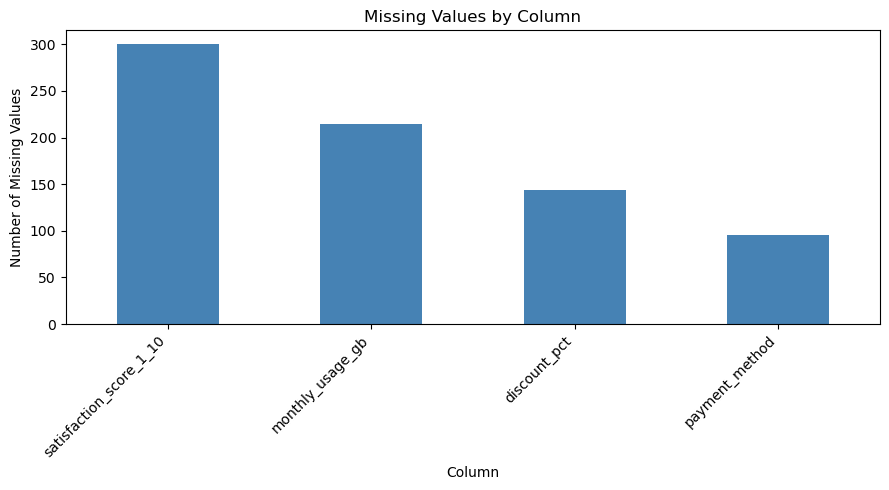

In [6]:
missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

ax = missing_counts.plot(kind="bar", figsize=(9, 5), color="steelblue")
ax.set_title("Missing Values by Column")
ax.set_xlabel("Column")
ax.set_ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [7]:
df.duplicated().sum()

np.int64(0)

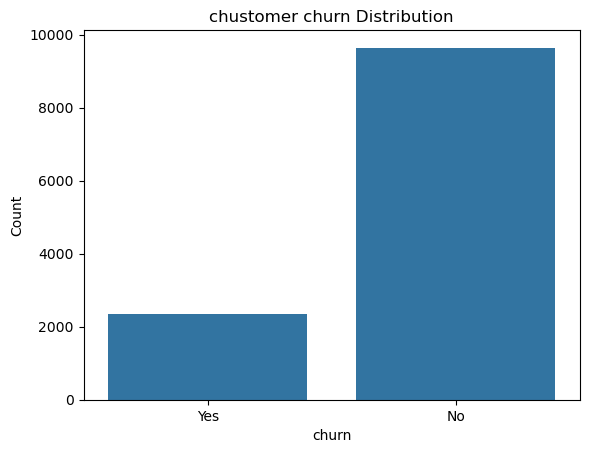

In [8]:
sns.countplot(data=df, x='churn')
plt.title('chustomer churn Distribution')
plt.ylabel('Count')
plt.show()

# EDA

churn             No   Yes
contract_type             
Month-to-month  4863  1787
One year        2888   429
Two year        1894   139


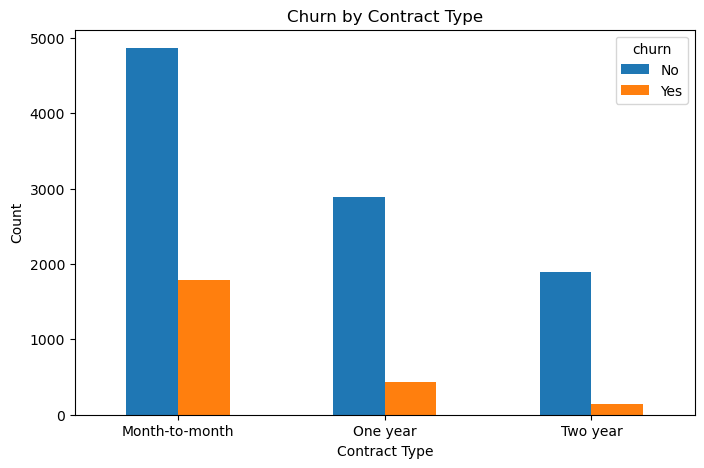

In [9]:
#churn by contract type 
churn_by_contract = pd.crosstab(df['contract_type'], df['churn'])
print(churn_by_contract)

churn_by_contract.plot(kind='bar', figsize=(8,5))
plt.title('Churn by Contract Type')
plt.ylabel('Count')
plt.xlabel('Contract Type')
plt.xticks(rotation=0)
plt.show()


churn               No  Yes
payment_method             
Bank transfer     2473  556
Credit card       2104  460
Electronic check  2842  818
UPI               2147  504


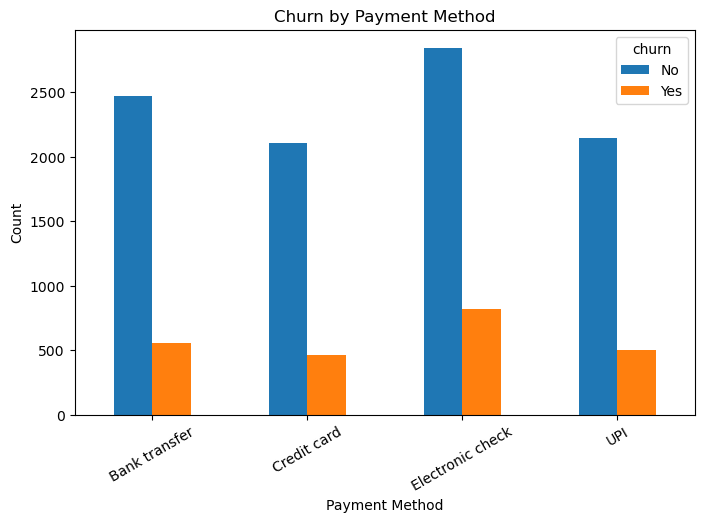

In [10]:
# churn by payment method 
churn_by_payment = pd.crosstab(df['payment_method'], df['churn'])
print(churn_by_payment)

churn_by_payment.plot(kind='bar', figsize=(8,5))
plt.title('Churn by Payment Method')
plt.ylabel('Count')
plt.xlabel('Payment Method')
plt.xticks(rotation=30)
plt.show()

In [11]:
# prepare the data for machine learning 
from sklearn.model_selection import train_test_split

# target variable 
Y=df['churn'].map({'No':0, 'Yes':1})

# input features 

X = df.drop(columns=['churn', 'customer_id'])

In [13]:
# Remove rows only if the target labels itself is missing or invalid 



valid_target = Y.notna()

X = X[valid_target]
Y = Y[valid_target]

In [14]:
# lit before fitting preprocessing steps to prevent data Leakage 

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42,) 


In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Separate columns by type
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist() 
categorical_features = X_train.select_dtypes(include =["object", 'category', 'bool']).columns.tolist()

print("Numerical Features:", numeric_features)
print("Categorical features:", categorical_features)


Numerical Features: ['tenure_months', 'monthly_charges_inr', 'total_charges_inr', 'support_tickets_90d', 'late_payments_6m', 'monthly_usage_gb', 'data_overage_count_6m', 'complaints_6m', 'discount_pct', 'satisfaction_score_1_10']
Categorical features: ['contract_type', 'internet_service', 'payment_method', 'region', 'autopay_enabled', 'family_plan']


In [23]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("\nPreprocessing pipeline created.")


Preprocessing pipeline created.


In [24]:
# train the Logistic Regression model using a pipeline
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))

])

model.fit(X_train, Y_train)
print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [25]:
y_pred = model.predict(X_test)
print(y_pred)

[1 0 1 ... 0 0 0]


In [26]:
from sklearn.metrics import classification_report

print(classification_report(Y_test, y_pred, target_names=["No churn", "Churn"]))

              precision    recall  f1-score   support

    No churn       0.91      0.72      0.81      1902
       Churn       0.41      0.72      0.52       498

    accuracy                           0.72      2400
   macro avg       0.66      0.72      0.66      2400
weighted avg       0.80      0.72      0.75      2400



In [31]:
# Kmeans 

numeric_features=[
    "tenure_months",
    "monthly_charges_inr",
    "total_charges_inr",
    "support_tickets_90d",
    "late_payments_6m",
    "monthly_usage_gb",
    "data_overage_count_6m",
    "complaints_6m",
    "discount_pct",
    "satisfaction_score_1_10"
]  

In [32]:
x = df[numeric_features].copy()
print("feature selection :", x.columns.tolist())
x.head()

feature selection : ['tenure_months', 'monthly_charges_inr', 'total_charges_inr', 'support_tickets_90d', 'late_payments_6m', 'monthly_usage_gb', 'data_overage_count_6m', 'complaints_6m', 'discount_pct', 'satisfaction_score_1_10']


,tenure_months,monthly_charges_inr,total_charges_inr,support_tickets_90d,late_payments_6m,monthly_usage_gb,data_overage_count_6m,complaints_6m,discount_pct,satisfaction_score_1_10
0,7,880.98,5751.83,2,0,23.4,0,0,8.4,5.3
1,56,870.97,49241.73,1,0,236.8,0,1,16.0,8.1
2,48,585.68,27360.91,2,0,0.0,0,1,9.9,6.1
3,32,967.32,30876.21,1,2,111.6,1,1,1.0,6.2
4,32,673.81,20782.63,1,2,48.2,0,1,9.3,5.7


In [39]:
# is `NameError`: `x_imputed_df` is undefined. You created `X_imputed`, so use that variable when building the DataFrame:
# 
X_imputed = imputer.fit_transform(x)
x_imputed = pd.DataFrame(X_imputed, columns=numeric_features, index=x.index)
print("Missing values after imputation:", x_imputed.isnull().sum()) 

Missing values after imputation: tenure_months              0
monthly_charges_inr        0
total_charges_inr          0
support_tickets_90d        0
late_payments_6m           0
monthly_usage_gb           0
data_overage_count_6m      0
complaints_6m              0
discount_pct               0
satisfaction_score_1_10    0
dtype: int64


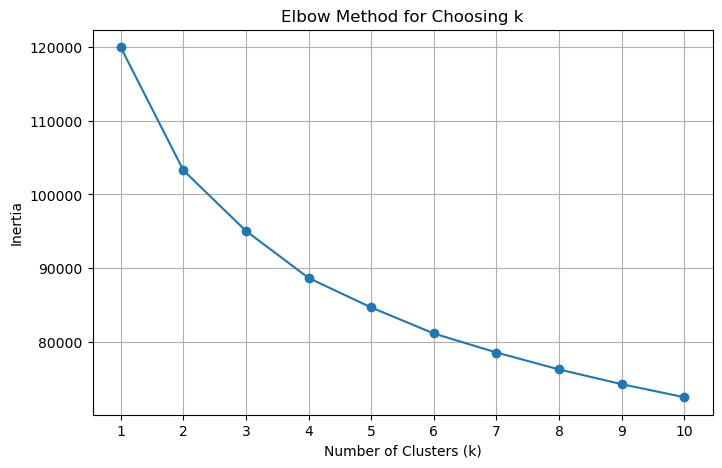

In [40]:
# elbow method to find the optimal number of clusters


from sklearn.cluster import KMeans

# Impute missing values and scale features for K-means
x_scaled = StandardScaler().fit_transform(
    SimpleImputer(strategy="median").fit_transform(x)
)

k_values = range(1, 11)
inertias = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(x_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.title("Elbow Method for Choosing k")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()